# Dự đoán rủi ro hủy/hoàn trả đơn hàng Amazon

Notebook triển khai quy trình phân loại nhị phân, kiểm soát rò rỉ dữ liệu và so sánh Decision Tree với Random Forest trên báo cáo bán hàng Amazon. Chạy lần lượt 6 giai đoạn bên dưới. CSV được đọc từ thư mục hiện tại nếu có, nếu không sẽ dùng đường dẫn dữ liệu đính kèm.

> Lưu ý: `Status` và các trường phát sinh sau khi đặt hàng không được dùng làm đặc trưng. Tập member gồm 1.000 đơn mới nhất, không dùng nhãn khi dự đoán nghiệp vụ.

## Giai đoạn 1 — Import thư viện và cấu hình hiển thị

Nạp các thư viện thao tác dữ liệu, trực quan hóa, tiền xử lý, chia tập, huấn luyện và đánh giá mô hình.

In [3]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans", "Liberation Sans"]
plt.rcParams["axes.unicode_minus"] = False


## Giai đoạn 2 — Làm sạch, tạo nhãn/đặc trưng và tách tập member

Loại các đơn chưa có kết quả, tạo nhãn hủy/hoàn trả, trích xuất đặc trưng thời gian/khuyến mãi/khu vực. Chỉ giữ danh sách 11 đặc trưng được xác định trước; sau đó sắp xếp theo thời gian và dành 1.000 đơn mới nhất làm dữ liệu nghiệp vụ chưa biết nhãn.

In [4]:
# Prefer the CSV beside this notebook, with the attached dataset as a fallback.
local_csv = "Amazon Sale Report.csv"
attached_csv = r"C:\baitieuluan.python\Amazon Sale Report.csv (1) (1)\Amazon Sale Report.csv"
csv_path = local_csv if os.path.exists(local_csv) else attached_csv
if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"CSV not found at {local_csv!r} or {attached_csv!r}. "
        "Place Amazon Sale Report.csv beside the notebook or update attached_csv."
    )

df = pd.read_csv(
    r'C:\baitieuluan.python\Amazon Sale Report.csv (1) (1)\Amazon Sale Report.csv',
    low_memory=False
)
df.columns = df.columns.str.strip()

pending_statuses = ["Pending", "Pending - Waiting for Pick Up", "Shipping"]
cancelled_statuses = [
    "Cancelled",
    "Shipped - Returned to Seller",
    "Shipped - Returning to Seller",
    "Shipped - Rejected by Buyer",
]
df = df.loc[~df["Status"].isin(pending_statuses)].copy()
df["is_cancelled_or_returned"] = df["Status"].isin(cancelled_statuses).astype("int8")

# Create features only from information available at order time.
df["Date"] = pd.to_datetime(df["Date"], format="%m-%d-%y")
df["day_of_week"] = df["Date"].dt.day_of_week
df["month"] = df["Date"].dt.month
df["has_promotion"] = df["promotion-ids"].notna().astype("int8")
df["B2B"] = df["B2B"].astype(int)
df["ship-state"] = df["ship-state"].astype("string").str.strip().str.upper()
top_states = df["ship-state"].value_counts().head(15).index
df["ship_state_grouped"] = df["ship-state"].where(df["ship-state"].isin(top_states), "OTHER").fillna("OTHER")

features = [
    "Fulfilment", "Sales Channel", "ship-service-level", "Category", "Size",
    "Amount", "ship_state_grouped", "B2B", "day_of_week", "month", "has_promotion",
]
leakage_and_identifier_columns = [
    "Qty", "Courier Status", "Unnamed: 22", "currency", "ship-country",
    "fulfilled-by", "index", "Order ID", "SKU", "ASIN", "Style",
]

df = df.sort_values("Date", ascending=True).reset_index(drop=True)
if len(df) != 128_028:
    raise ValueError(f"Expected 128,028 rows after removing pending statuses; found {len(df):,}.")
if len(df) <= 1_000:
    raise ValueError("At least 1,001 rows are required to reserve the member set.")

df_member = df.tail(1_000).copy()
df_model = df.iloc[:-1_000].copy()
# Keep member labels out of the prediction workflow.
df_member = df_member.drop(columns=["Status", "is_cancelled_or_returned"])
# Exclude leakage fields and identifiers from model inputs.
df_model = df_model.drop(columns=leakage_and_identifier_columns, errors="ignore")

assert len(df_member) == 1_000 and len(df_model) == 127_028
print(f"Số dòng sau khi bỏ đơn chờ: {len(df):,}")
print(f"df_model: {len(df_model):,} | df_member: {len(df_member):,}")
print("Tỷ lệ nhãn trên df_model:")
display(
    df_model["is_cancelled_or_returned"]
    .value_counts(normalize=True)
    .rename(index={0: "Giao thành công", 1: "Hủy/hoàn trả"})
    .rename("Tỷ lệ")
    .to_frame()
)


Số dòng sau khi bỏ đơn chờ: 128,028
df_model: 127,028 | df_member: 1,000
Tỷ lệ nhãn trên df_model:


,Tỷ lệ
is_cancelled_or_returned,
Giao thành công,0.840547
Hủy/hoàn trả,0.159453


## Giai đoạn 3 — Chia Train/Validation/Test và xây dựng bộ tiền xử lý

Tách dữ liệu theo tỷ lệ 70/15/15 với stratify trước khi học bất kỳ thống kê tiền xử lý nào. Hai bộ biến đổi được fit duy nhất trên Train; Validation và Test chỉ được transform.

In [5]:
target = "is_cancelled_or_returned"
X = df_model[features].copy()
y = df_model[target].copy()

# Split 70% for Train; divide the remaining 30% evenly between Validation and Test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)
print(f"Train: {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Validation: {len(X_val):,} ({len(X_val) / len(X):.1%})")
print(f"Test: {len(X_test):,} ({len(X_test) / len(X):.1%})")

numeric_features = ["Amount", "B2B", "day_of_week", "month", "has_promotion"]
categorical_features = [
    "Fulfilment", "Sales Channel", "ship-service-level", "Category", "Size",
    "ship_state_grouped",
]

prep_raw = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="drop",
)
prep_scaled = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="drop",
)

# Fit imputers, scalers, and one-hot categories using Train only.
X_train_raw = prep_raw.fit_transform(X_train)
X_val_raw = prep_raw.transform(X_val)
X_test_raw = prep_raw.transform(X_test)
X_train_scaled = prep_scaled.fit_transform(X_train)
X_val_scaled = prep_scaled.transform(X_val)
X_test_scaled = prep_scaled.transform(X_test)
print("Kích thước ma trận đặc trưng:", X_train_raw.shape)


Train: 88,919 (70.0%)
Validation: 19,054 (15.0%)
Test: 19,055 (15.0%)
Kích thước ma trận đặc trưng: (88919, 47)


## Giai đoạn 4 — So sánh mô hình và kiểm định chéo

Đánh giá Decision Tree và Random Forest, mỗi loại ở dạng thường và `class_weight='balanced'`. Mỗi cấu hình được huấn luyện trên cả đặc trưng chưa chuẩn hóa và đã chuẩn hóa; báo cáo chỉ số lớp hủy và ROC-AUC. Cross-validation được đóng gói cùng tiền xử lý để tránh rò rỉ giữa các fold.

In [6]:
model_configs = [
    ("Decision Tree", "Mặc định", DecisionTreeClassifier(max_depth=12, random_state=42)),
    ("Decision Tree", "Balanced", DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42)),
    ("Random Forest", "Mặc định", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("Random Forest", "Balanced", RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1)),
]

results = []
fitted_models = {}
for model_name, weight_name, base_model in model_configs:
    raw_model = base_model
    raw_model.fit(X_train_raw, y_train)
    scaled_model = type(base_model)(**base_model.get_params())
    scaled_model.fit(X_train_scaled, y_train)
    fitted_models[(model_name, weight_name, "raw")] = raw_model
    fitted_models[(model_name, weight_name, "scaled")] = scaled_model

    y_pred = raw_model.predict(X_test_raw)
    y_prob = raw_model.predict_proba(X_test_raw)[:, 1]
    results.append({
        "Mô hình": f"{model_name} ({weight_name})",
        "Acc (Chưa chuẩn hóa)": accuracy_score(y_test, y_pred),
        "Acc (Đã chuẩn hóa)": accuracy_score(y_test, scaled_model.predict(X_test_scaled)),
        "Precision (Hủy)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall (Hủy)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-Score (Hủy)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

# Keep preprocessing inside the Pipeline so each CV fold fits transforms on its own training split.
cv_pipeline = Pipeline([
    ("preprocessor", prep_raw),
    ("classifier", RandomForestClassifier(
        n_estimators=100, max_depth=12, class_weight="balanced",
        random_state=42, n_jobs=-1,
    )),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc_scores = cross_val_score(
    cv_pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1
)
print(f"Random Forest 5-fold ROC-AUC: {cv_auc_scores.mean():.4f} ± {cv_auc_scores.std():.4f}")


,Mô hình,Acc (Chưa chuẩn hóa),Acc (Đã chuẩn hóa),Precision (Hủy),Recall (Hủy),F1-Score (Hủy),ROC-AUC
0,Decision Tree (Mặc định),0.937287,0.937182,0.945841,0.643633,0.766007,0.913859
1,Decision Tree (Balanced),0.864760,0.864602,0.554948,0.767687,0.644208,0.915701
2,Random Forest (Mặc định),0.936605,0.936605,0.997284,0.604146,0.752459,0.925892
3,Random Forest (Balanced),0.853949,0.853897,0.528868,0.771635,0.627593,0.923719


Random Forest 5-fold ROC-AUC: 0.9251 ± 0.0030


## Giai đoạn 5 — Trực quan hóa kết quả và phân tích overfitting

Ba biểu đồ gồm ma trận nhầm lẫn của Random Forest balanced, F1 Train/Test theo độ sâu cho hai mô hình balanced, và 10 đặc trưng quan trọng nhất. Hình được hiển thị và lưu thành `bieu_do_bao_cao_btl.png`.

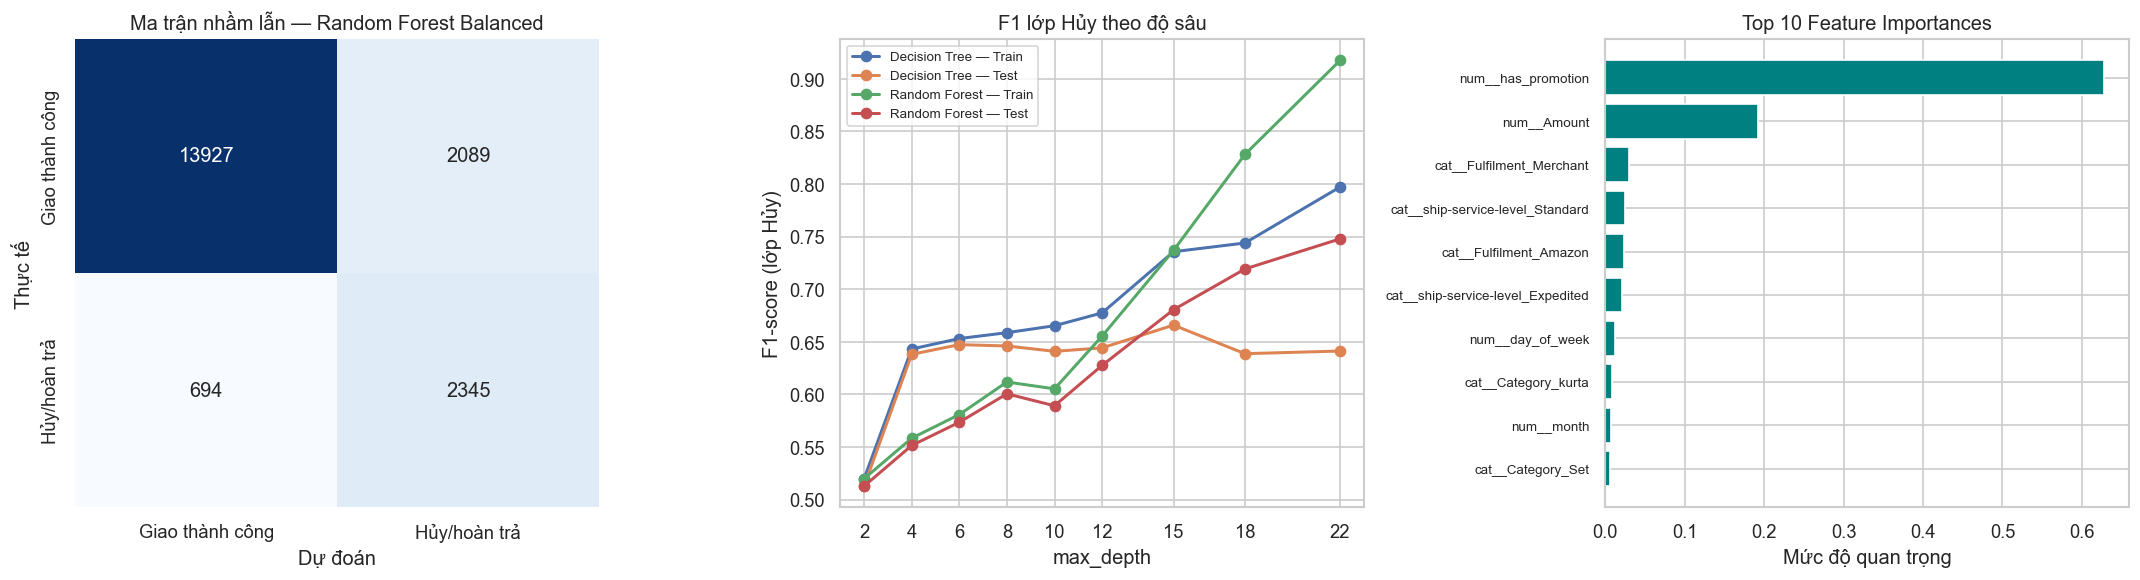

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix for the balanced Random Forest on Test.
balanced_rf = fitted_models[("Random Forest", "Balanced", "raw")]
y_test_pred_rf = balanced_rf.predict(X_test_raw)
cm = confusion_matrix(y_test, y_test_pred_rf, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Giao thành công", "Hủy/hoàn trả"],
    yticklabels=["Giao thành công", "Hủy/hoàn trả"],
)
axes[0].set_title("Ma trận nhầm lẫn — Random Forest Balanced")
axes[0].set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")

# Compare Train/Test F1 by max_depth for both balanced classifiers.
depths = [2, 4, 6, 8, 10, 12, 15, 18, 22]
depth_scores = {
    "Decision Tree — Train": [], "Decision Tree — Test": [],
    "Random Forest — Train": [], "Random Forest — Test": [],
}
for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=42)
    dt.fit(X_train_raw, y_train)
    depth_scores["Decision Tree — Train"].append(f1_score(y_train, dt.predict(X_train_raw), pos_label=1, zero_division=0))
    depth_scores["Decision Tree — Test"].append(f1_score(y_test, dt.predict(X_test_raw), pos_label=1, zero_division=0))

    rf = RandomForestClassifier(
        n_estimators=100, max_depth=depth, class_weight="balanced",
        random_state=42, n_jobs=-1,
    )
    rf.fit(X_train_raw, y_train)
    depth_scores["Random Forest — Train"].append(f1_score(y_train, rf.predict(X_train_raw), pos_label=1, zero_division=0))
    depth_scores["Random Forest — Test"].append(f1_score(y_test, rf.predict(X_test_raw), pos_label=1, zero_division=0))

for label, values in depth_scores.items():
    axes[1].plot(depths, values, marker="o", linewidth=1.8, label=label)
axes[1].set_title("F1 lớp Hủy theo độ sâu")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("F1-score (lớp Hủy)")
axes[1].set_xticks(depths)
axes[1].legend(fontsize=8)

# Top 10 feature importances from the balanced Random Forest.
feature_names = prep_raw.get_feature_names_out()
importances = pd.Series(balanced_rf.feature_importances_, index=feature_names)
top_features = importances.nlargest(10).sort_values()
axes[2].barh(top_features.index, top_features.values, color="teal")
axes[2].set_title("Top 10 Feature Importances")
axes[2].set_xlabel("Mức độ quan trọng")
axes[2].tick_params(axis="y", labelsize=8)

fig.tight_layout()
fig.savefig("bieu_do_bao_cao_btl.png", dpi=150, bbox_inches="tight")
plt.show()


## Giai đoạn 6 — Đánh giá cuối cùng và dự đoán tập member

Huấn luyện Pipeline Random Forest balanced trên Train, đối chiếu ROC-AUC trên Validation và Test. Sau đó dự đoán xác suất trên 1.000 đơn mới nhất, gán nhóm rủi ro theo ngưỡng yêu cầu và xuất kết quả CSV.

In [8]:
final_pipeline = Pipeline([
    ("preprocessor", prep_scaled),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])
final_pipeline.fit(X_train, y_train)

val_prob = final_pipeline.predict_proba(X_val)[:, 1]
test_prob = final_pipeline.predict_proba(X_test)[:, 1]
print(f"Validation ROC-AUC: {roc_auc_score(y_val, val_prob):.4f}")
print(f"Test ROC-AUC:       {roc_auc_score(y_test, test_prob):.4f}")

member_prob = final_pipeline.predict_proba(df_member[features])[:, 1]
df_member["Xac_suat_huy (%)"] = member_prob * 100
df_member["Phan_loai_rui_ro"] = np.select(
    [df_member["Xac_suat_huy (%)"] >= 70, df_member["Xac_suat_huy (%)"] >= 40],
    ["Rủi ro CAO", "Rủi ro TRUNG BÌNH"],
    default="An toàn",
)

risk_distribution = (
    df_member["Phan_loai_rui_ro"]
    .value_counts()
    .rename_axis("Nhóm rủi ro")
    .to_frame("Số đơn")
)
risk_distribution["Tỷ lệ (%)"] = risk_distribution["Số đơn"] / len(df_member) * 100
display(risk_distribution)

output_columns = [
    "Order ID", "Date", "Fulfilment", "Category", "Amount",
    "Xac_suat_huy (%)", "Phan_loai_rui_ro",
]
output_path = "ket_qua_du_doan_tap_member.csv"
df_member[output_columns].to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"Đã xuất {len(df_member):,} dự đoán tới: {output_path}")


Validation ROC-AUC: 0.9341
Test ROC-AUC:       0.9266


,Số đơn,Tỷ lệ (%)
Nhóm rủi ro,,
An toàn,570,57.0
Rủi ro TRUNG BÌNH,289,28.9
Rủi ro CAO,141,14.1


Đã xuất 1,000 dự đoán tới: ket_qua_du_doan_tap_member.csv
